# Physics-Informed Neural Networks for Urban Air Pollution Modelling
### Analysis, simulation and prediction of PM$_{2.5}$ over Delhi

This notebook is the computational companion to the report (`report/main.pdf`). It reads like a short paper:
each section states **what** we do, **why**, the **mathematics**, the **algorithm**, and then **interprets** the output.

**How it runs.** Everything below executes top to bottom in a few minutes on a laptop:

* the mathematical checks (autograd derivatives, exact Gaussian-puff solution, solver convergence, stability) run **live**;
* a short PINN-versus-data-only training run on the synthetic twin runs **live** (a demonstration, fewer iterations than the study);
* the headline results (4 + 6 full training runs of 6000 iterations, several hours of CPU time) are **loaded** from
  `results/metrics/`, which the scripts in `experiments/` produce. The commands to regenerate them are in the last section.

**Labels.** Every quantity is tagged as **OBSERVED** (monitor measurements), **ESTIMATED** (ERA5 reanalysis),
**CALIBRATED** (learned by the PINN) or **SYNTHETIC** (generated by our solver).

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import Image, display

cfg = yaml.safe_load(open("config/config.yaml"))
SEED = cfg["seed"]
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "font.size": 9})
COL = {"PINN": "#2a78d6", "DataOnlyNN": "#eb6834", "IDW": "#1baf7a", "RandomForest": "#eda100", "StationMean": "#6250d6"}
FIG = ROOT / "results" / "figures"
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| seed", SEED)

numpy 2.5.4 | pandas 3.1.0 | torch 2.15.0 | seed 42


## 1. Real-world data

**What.** Hourly PM$_{2.5}$ from regulatory monitors (CPCB, DPCC, IMD, IITM) in Delhi, obtained from the
OpenAQ open-data archive, and hourly ERA5 reanalysis wind and boundary-layer height from Open-Meteo.

**Why.** The brief requires real observations with verifiable provenance. Delhi has one of the densest regulatory networks
in India (about 45 usable monitors in a 50 km box), which is what a *spatial* model needs.

**Cleaning algorithm** (`src/data/preprocessing.py`, 13 unit tests):
1. keep PM$_{2.5}$, reject units other than µg/m³;
2. drop sentinels (`-999`), negatives and values $> 2000$ µg/m³;
3. convert IST to UTC, average 15-minute values to hourly means (this also collapses duplicate timestamps);
4. remove stuck sensors (≥ 6 identical consecutive hours);
5. drop stations outside the study box or with < 75 % hourly coverage.

The winter window was planned for November 2024, but the archive holds no CPCB/DPCC files for that month,
so it was moved to the same dates in 2025.

In [2]:
report = pd.DataFrame(json.load(open("results/metrics/real_cleaning.json"))).T
obs = {w: pd.read_csv(f"data/processed/real/{w}_observations.csv", parse_dates=["time"]) for w in ("winter", "spring")}
forcing = {w: pd.read_csv(f"data/processed/real/{w}_forcing.csv", parse_dates=["time"]) for w in ("winter", "spring")}
report[["raw_pm25_records", "after_cleaning", "after_coverage", "stations", "start_utc", "end_utc"]]

,raw_pm25_records,after_cleaning,after_coverage,stations,start_utc,end_utc
winter,43339,12516,9828,45,2025-11-09 18:30:00+00:00,2025-11-19 18:30:00+00:00
spring,45039,12619,9693,42,2025-02-28 18:30:00+00:00,2025-03-10 18:30:00+00:00


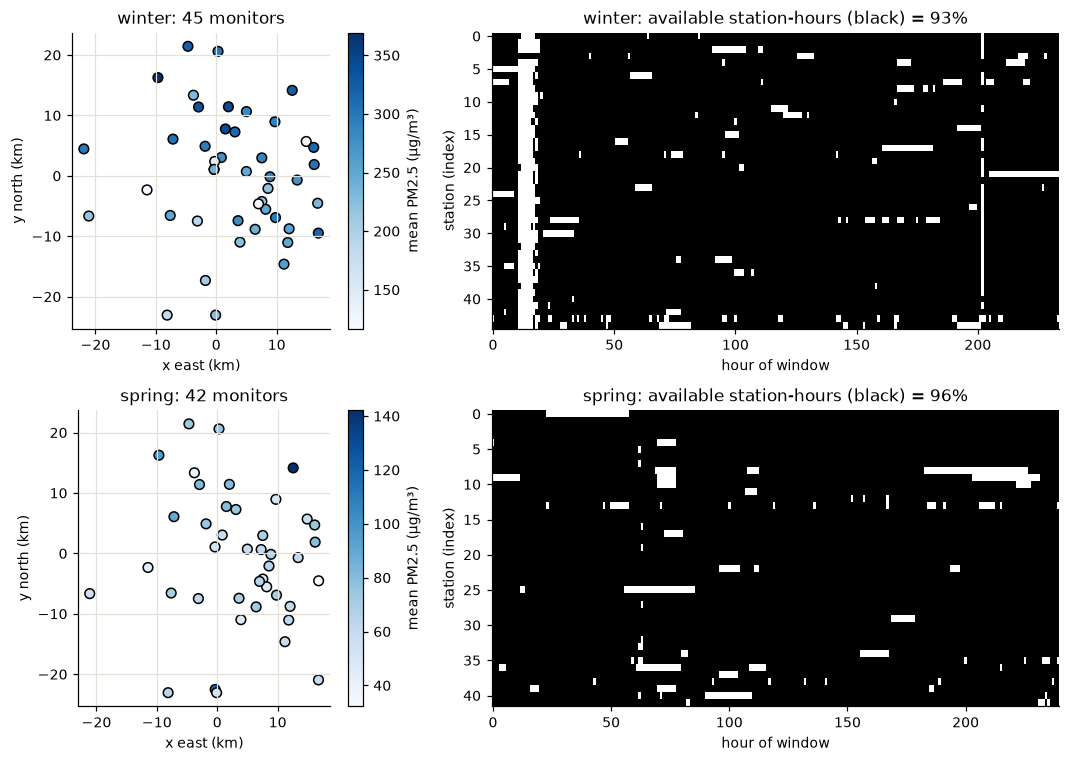

In [3]:
# OBSERVED: station locations (local km grid) coloured by window-mean PM2.5, and data availability per station-hour.
fig, axs = plt.subplots(2, 2, figsize=(10, 7), gridspec_kw=dict(width_ratios=[1, 1.6]))
for row, w in enumerate(obs):
    o = obs[w]
    st = o.groupby("location_id").agg(x=("x", "first"), y=("y", "first"), mean=("pm25", "mean"))
    sc = axs[row, 0].scatter(st.x, st.y, c=st["mean"], cmap="Blues", edgecolors="k", s=40)
    plt.colorbar(sc, ax=axs[row, 0], label="mean PM2.5 (µg/m³)")
    axs[row, 0].set(aspect="equal", xlabel="x east (km)", ylabel="y north (km)", title=f"{w}: {len(st)} monitors")
    avail = o.pivot_table(index="location_id", columns="time", values="pm25", aggfunc="size").notna()
    axs[row, 1].imshow(avail.values, aspect="auto", cmap="Greys", interpolation="nearest")
    axs[row, 1].set(xlabel="hour of window", ylabel="station (index)",
                    title=f"{w}: available station-hours (black) = {avail.values.mean():.0%}")
    axs[row, 1].grid(False)
plt.tight_layout(); plt.show()

**Interpretation.** Coverage after cleaning is above 90 % of station-hours; gaps are short and scattered, so the
data loss simply uses the hours that exist (no gap-filling, no interpolated "observations"). Concentrations differ
markedly between stations, which is the spatial signal a model must reconstruct at held-out monitors.

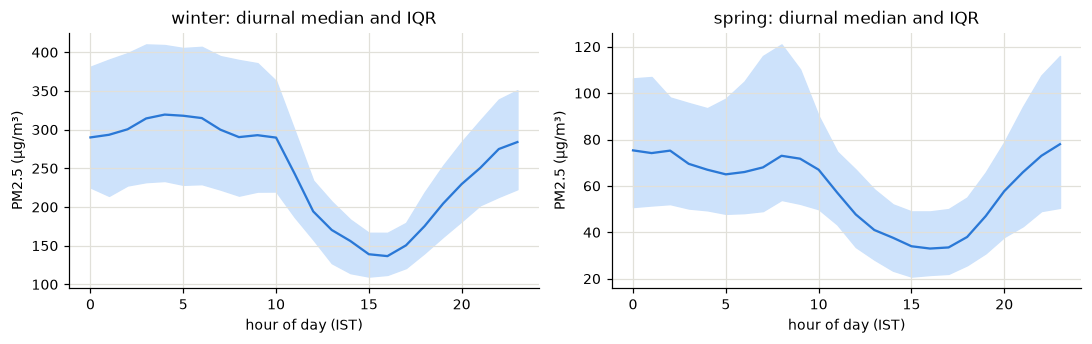

winter: mean 258 µg/m³, median inter-station correlation r = 0.70
spring: mean 67 µg/m³, median inter-station correlation r = 0.73


In [4]:
# OBSERVED: temporal structure and how much of it is shared between stations.
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, w in zip(axs, obs):
    o = obs[w].assign(hour=(obs[w].time.dt.tz_convert("Asia/Kolkata").dt.hour))
    q = o.groupby("hour").pm25.quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color="#cde2fb"); ax.plot(q.index, q[0.5], color=COL["PINN"])
    ax.set(xlabel="hour of day (IST)", ylabel="PM2.5 (µg/m³)", title=f"{w}: diurnal median and IQR")
plt.tight_layout(); plt.show()
for w, o in obs.items():
    c = o.pivot_table(index="time", columns="location_id", values="pm25").corr().values
    print(f"{w}: mean {o.pm25.mean():.0f} µg/m³, median inter-station correlation r = {np.nanmedian(c[np.triu_indices_from(c, 1)]):.2f}")

**Interpretation.** Both windows peak at night and bottom out in mid-afternoon — the signature of the boundary layer
collapsing at night and deepening by day, which is why the mixing height enters our source term. The median
inter-station correlation of about 0.7 says that much of the variation is shared across the city; this will matter
when we interpret the real-data results.

## 2. Mathematical model

Conservation of mass in a well-mixed layer of depth $H(t)$, with uniform wind, K-theory diffusion, linear removal and
a separable emission source, gives the 2D advection–diffusion–reaction equation

$$
\frac{\partial C}{\partial t} + u(t)\frac{\partial C}{\partial x} + v(t)\frac{\partial C}{\partial y}
= D\nabla^2 C - \lambda C + \frac{q(x,y)\,g(\tau)}{\max\{H(t),H_{\min}\}} .
$$

| Symbol | Meaning | Status |
|---|---|---|
| $C$ | PM$_{2.5}$ (µg m$^{-3}$) | observed at monitors |
| $u, v$ | 10 m wind (m s$^{-1}$) | estimated (ERA5) |
| $H$ | boundary-layer height (m), floored at $H_{\min}=50$ m | estimated (ERA5) |
| $D$ | eddy diffusivity (m$^2$ s$^{-1}$), bounded to [10, 2000] | calibrated |
| $\lambda$ | removal rate, $5\times10^{-6}$ s$^{-1}$ | fixed |
| $q(x,y)\ge 0$, $g(\tau)$ | emission flux field and 24-h profile (mean 1) | calibrated |

**Assumptions:** well-mixed layer (2D), spatially uniform wind, constant isotropic $D$, linear removal,
separable emissions, unknown inflow (weak outflow condition only), no entrainment term.

### Dimensionless groups
Scaling $x' = (x-x_c)/L$, $t' = 2t/T-1$, $C' = C/C_{\mathrm{ref}}$ gives coefficients $U=uT/2L$, $K=DT/2L^2$,
$\Lambda=\lambda T/2$. The physical groups are the Péclet number $\mathrm{Pe}=\bar u\ell/D$ and the Damköhler number
$\mathrm{Da}=\lambda\ell/\bar u$. We compute them from the real forcing:

In [5]:
from experiments.make_synthetic_twin import domain_km
xmin, xmax, ymin, ymax = domain_km(cfg["domain"])
ell = max(xmax - xmin, ymax - ymin) * 1e3       # m
lam = cfg["physics"]["lam"]
for w, f in forcing.items():
    ubar = f.wind_speed_10m.mean()
    print(f"{w}: mean wind {ubar:.2f} m/s | advection time l/u = {ell / ubar / 3600:.1f} h | "
          f"Pe = {ubar * ell / 1000:.0f}–{ubar * ell / 100:.0f} (D = 1000–100 m²/s) | Da = {lam * ell / ubar:.2f} | "
          f"H range {f.blh.min():.0f}–{f.blh.max():.0f} m")

winter: mean wind 1.41 m/s | advection time l/u = 10.5 h | Pe = 75–752 (D = 1000–100 m²/s) | Da = 0.19 | H range 25–1335 m
spring: mean wind 2.19 m/s | advection time l/u = 6.8 h | Pe = 117–1168 (D = 1000–100 m²/s) | Da = 0.12 | H range 15–2710 m


**Interpretation.** $\mathrm{Pe}\gg 1$: transport is dominated by the wind, and diffusion is a small correction —
so we should *expect* $D$ to be poorly identifiable. $\mathrm{Da}\ll 1$: removal is slow compared with transit.
Air crosses the city in 7–11 hours, so hourly data can, in principle, see transport between stations. The ERA5 mixing
height falls to 15–25 m on calm nights in these windows (and to ~10 m in the twin's forcing), which motivates the floor $H_{\min}=50$ m.

## 3. Mathematical analysis, checked numerically

### 3.1 Fourier stability and equilibrium
For constant coefficients, $C=\hat c\,e^{i\mathbf k\cdot\mathbf x+\sigma t}$ gives
$\sigma = -i\,\mathbf u\cdot\mathbf k - D|\mathbf k|^2 - \lambda$, so $\operatorname{Re}\sigma = -(D|\mathbf k|^2+\lambda) < 0$:
every mode decays (advection only rotates its phase). For a uniform constant source $S_0$ the uniform solution
$C(t) = S_0/\lambda + (C_0 - S_0/\lambda)e^{-\lambda t}$ tends to the stable equilibrium $C^* = S_0/\lambda$.

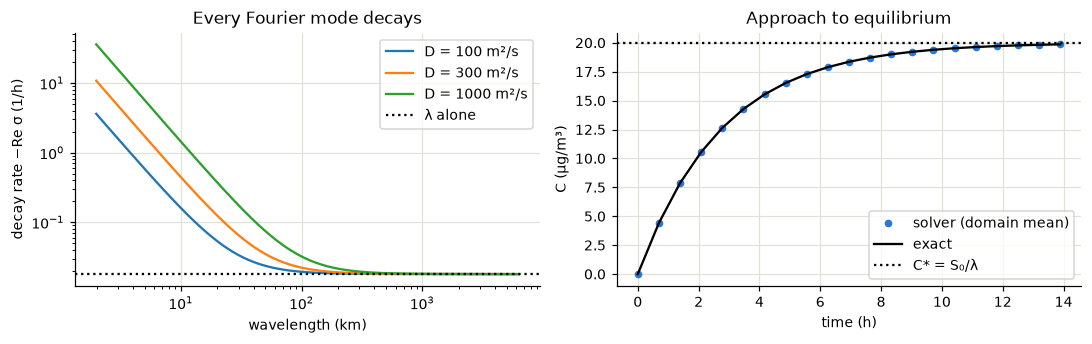

max relative error vs exact: 1.504053905035798e-06


In [6]:
from src.physics.solver import Grid, solve_adr
k = np.logspace(-6, -2.5, 200)                       # wavenumber (1/m)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for D in (100, 300, 1000):
    axs[0].loglog(2 * np.pi / k / 1e3, (D * k**2 + lam) * 3600, label=f"D = {D} m²/s")
axs[0].axhline(lam * 3600, color="k", ls=":", label="λ alone")
axs[0].set(xlabel="wavelength (km)", ylabel="decay rate −Re σ (1/h)", title="Every Fourier mode decays"); axs[0].legend()

# Equilibrium: uniform source and removal with the reference solver vs the exact solution.
g = Grid(-1e4, 1e4, -1e4, 1e4, 21, 21)
S0, lam_demo = 2e-3, 1e-4
exact = lambda t: S0 / lam_demo * (1 - np.exp(-lam_demo * t))
sol = solve_adr(g, np.zeros(g.shape), 50_000, lambda t: 1.5, lambda t: -0.5, 100.0, lam_demo,
                lambda X, Y, t: S0, exact, save_every=2500.0)
axs[1].plot(sol["t"] / 3600, sol["C"].mean(axis=(1, 2)), "o", ms=4, color=COL["PINN"], label="solver (domain mean)")
axs[1].plot(sol["t"] / 3600, exact(sol["t"]), "k-", label="exact")
axs[1].axhline(S0 / lam_demo, color="k", ls=":", label="C* = S₀/λ")
axs[1].set(xlabel="time (h)", ylabel="C (µg/m³)", title="Approach to equilibrium"); axs[1].legend()
plt.tight_layout(); plt.show()
print("max relative error vs exact:", np.max(np.abs(sol["C"].mean(axis=(1, 2)) - exact(sol["t"]))[1:] / exact(sol["t"][1:])))

**Interpretation.** Short wavelengths are damped fastest by diffusion; long ones decay at the removal rate $\lambda$.
The solver reproduces the exact approach to $C^*$, confirming the reaction and source terms and the boundary handling.

### 3.2 Automatic differentiation and the PDE residual
The PINN needs $\partial_t C$, $\partial_x C$, $\partial_y C$ and $\nabla^2 C$ of a neural network. We check our autograd
implementation (`src/physics/advection_diffusion.py`) against two independent references:
a manufactured function with known derivatives, and the **exact Gaussian puff**

$$C=\frac{M}{4\pi Dt}\exp\!\Big(-\frac{|\mathbf x-\mathbf x_0-\mathbf u t|^2}{4Dt}-\lambda t\Big),$$

which solves the PDE with $S=0$, so its residual must vanish.

In [7]:
from src.physics.advection_diffusion import adr_residual, gaussian_puff, gradients
X = torch.rand(500, 3, dtype=torch.float64, requires_grad=True)
x, y, t = X[:, 0], X[:, 1], X[:, 2]
C = torch.sin(2 * x) * torch.cos(3 * y) * torch.exp(-t)
d = gradients(C, X)
lap_exact = -13 * torch.sin(2 * x) * torch.cos(3 * y) * torch.exp(-t)
print("max |autograd Laplacian − analytic| =", (d["xx"] + d["yy"] - lap_exact).abs().max().item())

Xp = (torch.rand(500, 3, dtype=torch.float64) * torch.tensor([4.0, 4.0, 1.0]) + torch.tensor([-2.0, -2.0, 0.5])).requires_grad_(True)
u_, v_, D_, lam_ = 0.8, 0.3, 0.1, 0.2
Cp = gaussian_puff(Xp[:, 0], Xp[:, 1], Xp[:, 2], M=1.0, x0=0.0, y0=0.0, u=u_, v=v_, D=D_, lam=lam_)
print("max |PDE residual| of the exact puff =", adr_residual(Cp, Xp, u_, v_, D_, lam_, torch.zeros(500)).abs().max().item())

max |autograd Laplacian − analytic| = 3.552713678800501e-15
max |PDE residual| of the exact puff = 3.3306690738754696e-16


**Interpretation.** Both errors are at the level of floating-point round-off ($\sim 10^{-14}$), so the residual operator
used in training is exactly the PDE we wrote down.

### 3.3 Reference solver: discretisation, stability, convergence
Method of lines: third-order upwind-biased advection, second-order central diffusion, SSP-RK3 in time. Von Neumann
analysis bounds the time step by the Courant number $\Delta t(|u|/\Delta x+|v|/\Delta y)\le 0.5$ and the diffusion number
$D\Delta t(\Delta x^{-2}+\Delta y^{-2})\le 0.25$. We verify convergence to the exact puff under grid refinement:

In [8]:
def puff_error(n):
    g = Grid(-15e3, 15e3, -15e3, 15e3, n, n)
    p = lambda X, Y, t: gaussian_puff(X, Y, t, M=1e10, x0=-12e3, y0=-8e3, u=2.0, v=1.0, D=400.0, lam=1e-5)
    out = solve_adr(g, p(g.X, g.Y, 3600.0), 5400.0, lambda t: 2.0, lambda t: 1.0, 400.0, 1e-5,
                    lambda X, Y, t: 0.0, lambda t: 0.0, save_every=None, t0=3600.0)
    e = p(g.X, g.Y, 9000.0)
    return g.dx, np.linalg.norm(out["C"][-1] - e) / np.linalg.norm(e)

rows = [puff_error(n) for n in (41, 81, 161)]
conv = pd.DataFrame(rows, columns=["dx (m)", "relative L2 error"])
conv["observed order"] = [np.nan] + [np.log2(rows[i][1] / rows[i + 1][1]) for i in range(2)]
conv

,dx (m),relative L2 error,observed order
0,750.0,0.014171,NaN
1,375.0,0.001116,3.667027
2,187.5,0.000187,2.574668


**Interpretation.** Halving the grid spacing reduces the error by roughly an order of magnitude (observed orders between 2.6
and 3.7, consistent with third-order advection and second-order diffusion). The solver is therefore accurate enough to serve
as the "truth" of the synthetic twin.

## 4. The PINN

**Architecture** (`src/models/pinn.py`):
* concentration network $(x',y',t') \mapsto \hat C' = \mathrm{softplus}(\mathrm{MLP}_{5\times64}^{\tanh})$ — softplus keeps
  $C\ge 0$; $\tanh$ keeps second derivatives non-zero (ReLU would make $\nabla^2\hat C = 0$ almost everywhere);
* source model $S' = q(x',y')\,g(\tau)/h(t)$ with $q$ a small softplus MLP ($2\times 32$) and $g$ 24 hourly values with mean 1;
* bounded diffusivity $D = D_{\min} + (D_{\max}-D_{\min})\,\sigma(\theta_D)$.

Meteorology is **not** a network input, so $\partial \hat C/\partial t$ is a true partial derivative; the wind and mixing height
enter only through the PDE coefficients.

**Loss.**
$$\mathcal L = w_d\underbrace{\tfrac1{N_d}\textstyle\sum(\hat C'_j-C'_j)^2}_{\text{stations}}
+ w_p\underbrace{\tfrac1{N_c}\textstyle\sum r_k^2}_{\text{PDE residual}}
+ w_b\underbrace{\tfrac1{N_b}\textstyle\sum_{\mathbf u\cdot\mathbf n>0}(\nabla\hat C'\cdot\mathbf n)^2}_{\text{outflow}}
+ w_s\underbrace{\big(\overline{|\nabla q|^2} + \text{curvature of } g\big)}_{\text{source regulariser}}$$

The source regulariser is essential: an unrestricted source could absorb any residual and make the physics term vacuous.

**Algorithm.**
1. Sample 4096 Latin-hypercube collocation points and 512 boundary points in $[-1,1]^3$ (resampled every 250 steps).
2. Each step: evaluate the four loss terms (derivatives by autograd), take an Adam step; learning rate $10^{-3}\to10^{-4}$.
3. Every 100 steps, score the **validation stations** and keep the best weights (they never contribute gradients).

The **data-only network** is the identical model with $w_p=w_b=w_s=0$ — the controlled comparison.

### 4.1 Synthetic twin
To know whether the physics *can* help we need a case with a known answer. The reference solver, driven by the **real ERA5
wind and mixing height** of 12–15 November 2024 and an illustrative emission field, produces the truth; it is sampled at the
**45 real monitor locations** with 5 % noise (all SYNTHETIC).

{'kind': 'SYNTHETIC', 'station_layout': 'real_winter_monitor_coordinates', 'n_stations': 45, 'D_true': 300.0, 'lam_true': 5e-06, 'noise_rel': 0.05}
split sizes (stations): {'train': 30, 'val': 7, 'test': 8}


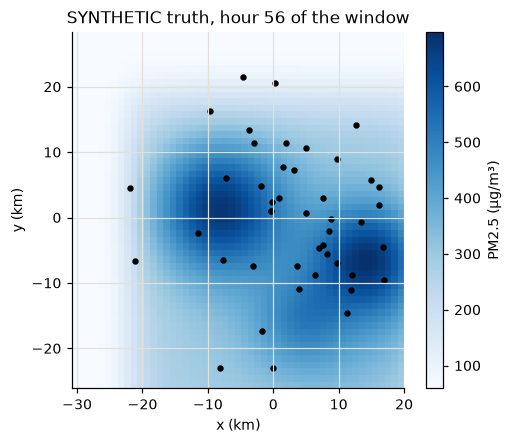

In [9]:
from experiments.run_twin import setup as twin_setup, new_model as twin_model, add_features
tw = twin_setup(SEED)
meta, truth = tw["meta"], tw["truth"]
print({k: meta[k] for k in ("kind", "station_layout", "n_stations", "D_true", "lam_true", "noise_rel")})
print("split sizes (stations):", {k: len(v) for k, v in tw["split"].items()})

k = int(np.argmax(truth["C"].reshape(len(truth["t_rel"]), -1).std(1)))
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.pcolormesh(truth["x"] / 1e3, truth["y"] / 1e3, truth["C"][k].T, cmap="Blues", shading="auto")
st = tw["obs"].drop_duplicates("location_id")
ax.scatter(st.x, st.y, s=10, c="k")
plt.colorbar(im, label="PM2.5 (µg/m³)"); ax.set(aspect="equal", xlabel="x (km)", ylabel="y (km)",
                                                 title=f"SYNTHETIC truth, hour {k} of the window")
plt.show()

### 4.2 Live demonstration: data-only network vs PINN
A shortened run (1500 iterations instead of 6000; seed 42 split, $w_p=0.01$). The full study's numbers follow in §4.3.

In [10]:
from src.training.trainer import TrainConfig, train
from src.evaluation.metrics import evaluate
sc, fz, part = tw["sc"], tw["fz"], tw["part"]
tens = lambda d: (sc.inputs(d.x * 1e3, d.y * 1e3, d.t_rel), torch.as_tensor(d.pm25.to_numpy() / sc.C_ref, dtype=torch.float32))
Xtr, ctr = tens(part["train"]); val = tens(part["val"]); test = part["test"]
gx, gy = np.meshgrid(truth["x"], truth["y"], indexing="ij")

demo, hist = {}, {}
for name, wp in (("DataOnlyNN", 0.0), ("PINN", 0.01)):
    m = twin_model(tw)
    t0 = time.time()
    hist[name] = train(m, Xtr, ctr, TrainConfig(n_iters=1500, seed=SEED, w_p=wp, w_b=0.1 if wp else 0.0,
                                                w_s=1e-3 if wp else 0.0, log_every=50), val=val)
    with torch.no_grad():
        p = m(sc.inputs(test.x * 1e3, test.y * 1e3, test.t_rel)).numpy() * sc.C_ref
        F = np.stack([m(sc.inputs(gx.ravel(), gy.ravel(), np.full(gx.size, tt))).numpy() * sc.C_ref
                      for tt in truth["t_rel"][::6]])
    field = np.sqrt(np.mean((F - truth["C"][::6].reshape(len(F), -1)) ** 2))
    demo[name] = {**{k_: round(v, 3) for k_, v in evaluate(test.pm25, p).items() if k_ in ("mae", "rmse", "r2")},
                  "field_rmse": round(float(field), 2), "D": round(m.D().item(), 1), "seconds": round(time.time() - t0)}
res = pd.DataFrame(demo).T
better = lambda col: "PINN" if res.loc["PINN", col] < res.loc["DataOnlyNN", col] else "data-only NN"
print(f"Lower whole-field RMSE: {better('field_rmse')} | lower held-out-station RMSE: {better('rmse')}")
res

Lower whole-field RMSE: PINN | lower held-out-station RMSE: data-only NN


,mae,rmse,r2,field_rmse,D,seconds
DataOnlyNN,20.382,28.231,0.963,59.20,300.0,3.0
PINN,23.026,32.325,0.951,49.25,175.3,53.0


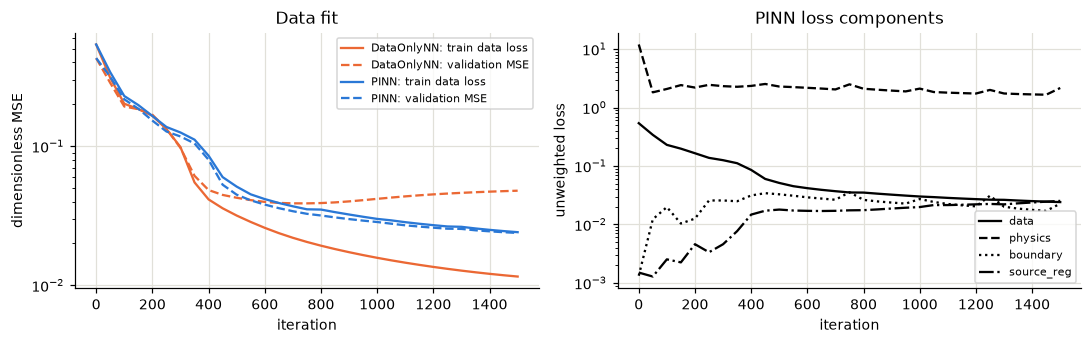

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for name, h in hist.items():
    it = [r["iter"] for r in h]
    axs[0].semilogy(it, [r["data"] for r in h], color=COL[name], label=f"{name}: train data loss")
    axs[0].semilogy(it, [r["val"] for r in h], color=COL[name], ls="--", label=f"{name}: validation MSE")
for key, ls in (("data", "-"), ("physics", "--"), ("boundary", ":"), ("source_reg", "-.")):
    axs[1].semilogy([r["iter"] for r in hist["PINN"]], [r[key] for r in hist["PINN"]], "k", ls=ls, label=key)
axs[0].set(xlabel="iteration", ylabel="dimensionless MSE", title="Data fit"); axs[0].legend(fontsize=7)
axs[1].set(xlabel="iteration", ylabel="unweighted loss", title="PINN loss components"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation.** In this shortened run the PINN already has the lower **whole-field** error (scored against the known
truth on the grid): the PDE carries information from the stations along the wind into the gaps between them. At the
**held-out stations** it may not yet be ahead — the PINN optimises a harder, multi-term objective and converges more
slowly (its data loss is still falling at 1500 iterations, while the data-only network has nearly fitted its stations).
This is why the study uses 6000 iterations; with the full schedule (below) the PINN is also better at the held-out stations
on average. The demonstration shows the mechanism; the full study is the reference for the numbers.

### 4.3 Full synthetic-twin results (loaded; 4 station splits, 6000 iterations)

In [12]:
twin = pd.read_csv("results/metrics/twin_seed_summary.csv")
twin.groupby("model")[["rmse", "mae", "field"]].agg(["mean", "std"]).round(1).loc[["IDW", "RandomForest", "DataOnlyNN", "PINN"]]

rmse        mae      field     
              mean  std  mean  std  mean  std
model                                        
IDW           43.8  9.5  28.8  6.4   NaN  NaN
RandomForest  43.8  5.6  27.0  3.0   NaN  NaN
DataOnlyNN    29.9  9.9  18.9  3.9  54.5  9.6
PINN          22.1  3.1  15.1  1.6  31.3  2.3

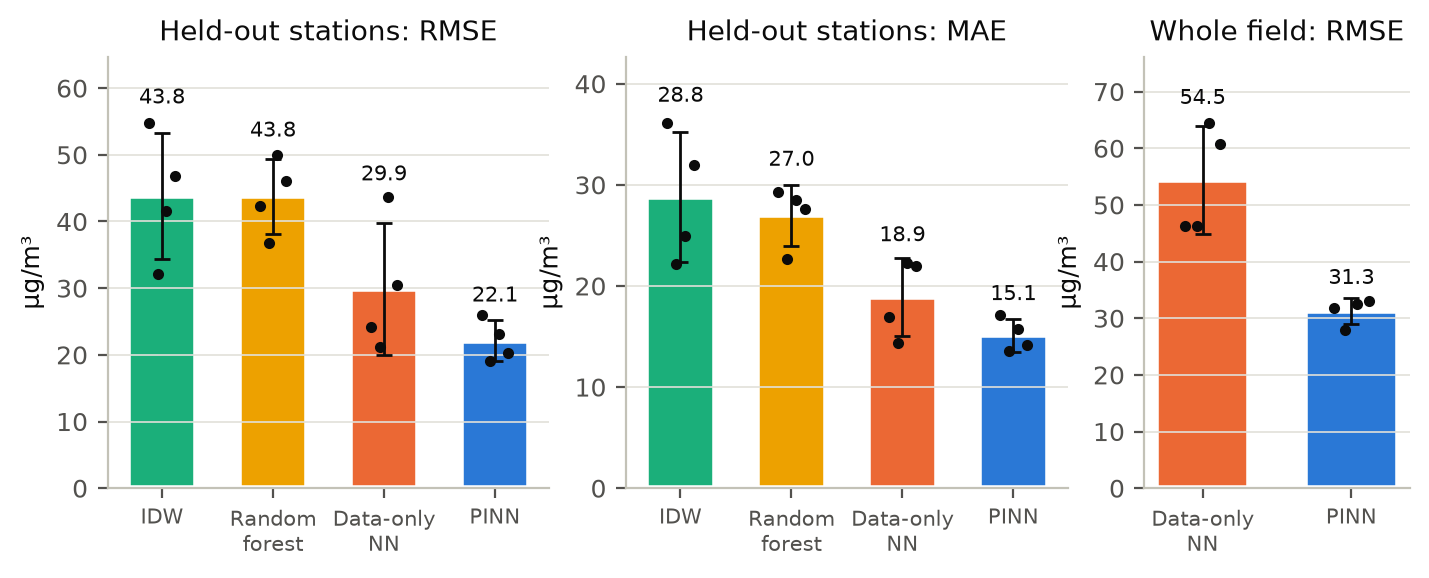

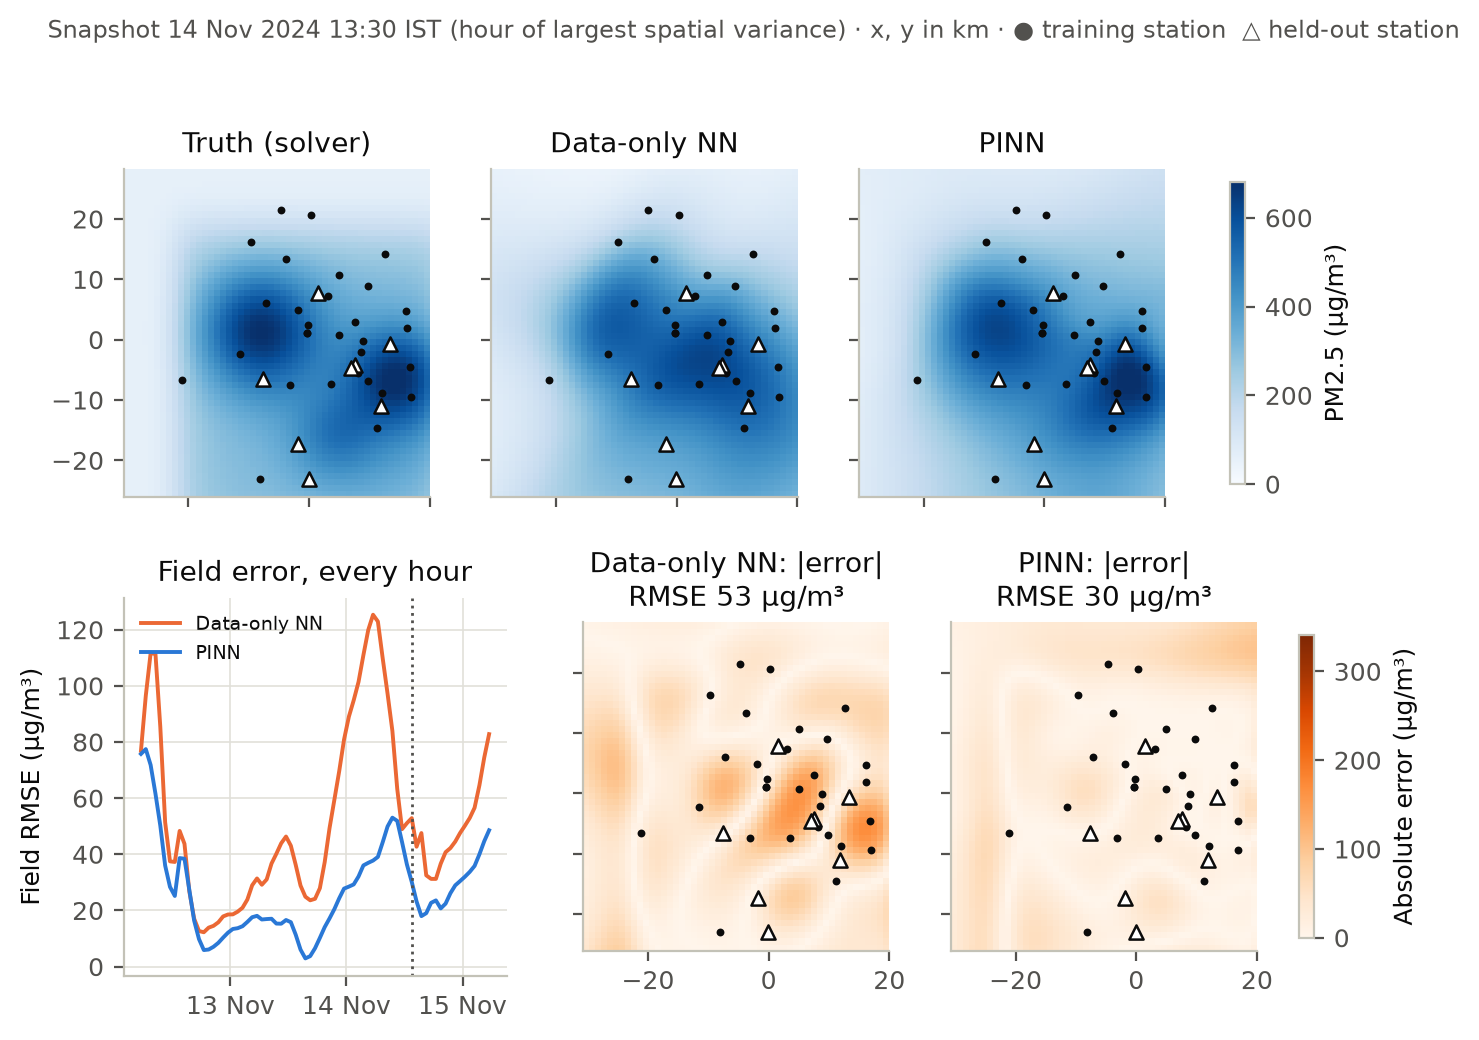

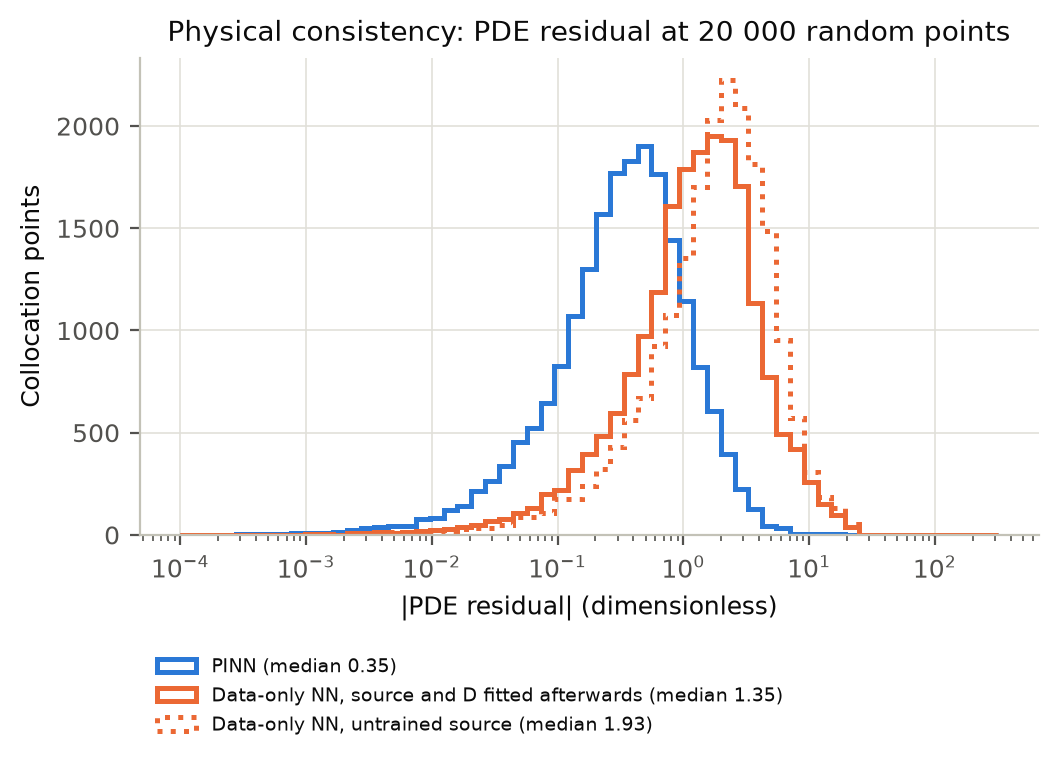

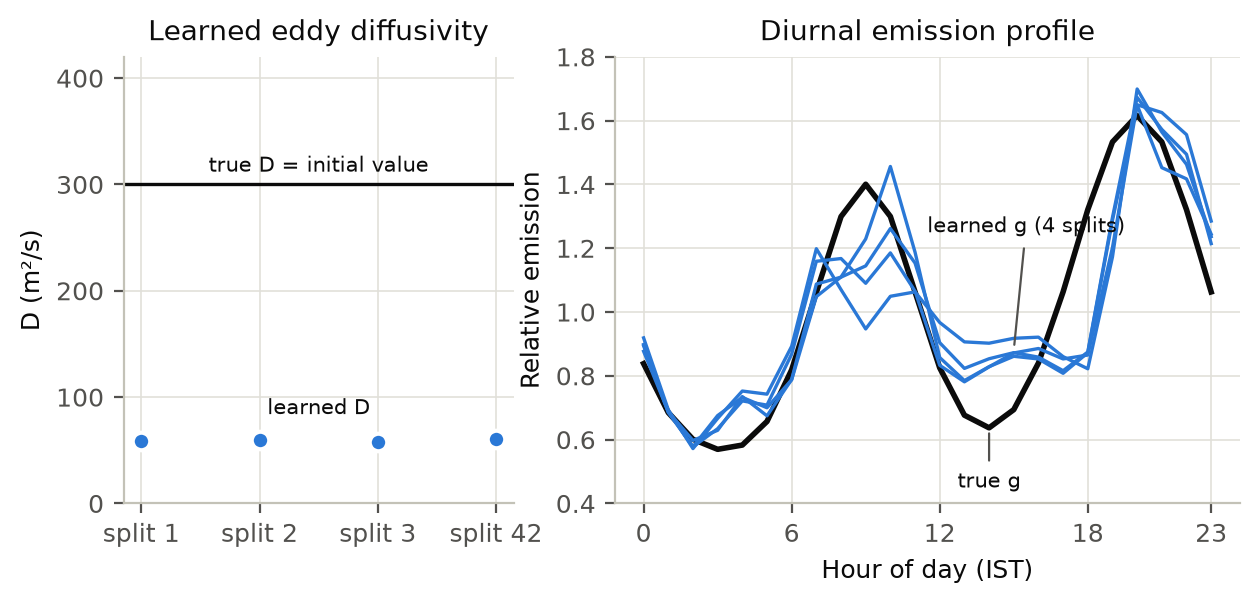

In [13]:
for f in ("twin_comparison", "twin_fields", "twin_residual", "twin_identifiability"):
    display(Image(filename=str(FIG / f"{f}.png"), width=850))

**Interpretation (SYNTHETIC).**
* The PINN has the lowest held-out error and the smallest spread across splits; over the whole field it is about 43 % more
  accurate than the identical network without physics.
* Its fields satisfy the PDE about 4× better, even after fitting an emission model to the data-only field — station fit
  alone does not produce a transport-consistent field.
* **Identifiability:** $D$ was initialised at its true value (300 m²/s) yet converges to ≈ 60 m²/s in every split,
  exactly as the Péclet-number analysis predicts; the diurnal emission profile, by contrast, is recovered well.

## 5. Observed data: held-out Delhi monitors

**Protocol.** Stations (not hours) are split 70/15/15 into train/validation/test, with co-located stations (< 1 km) kept
together; leakage is asserted in code; all models share the split. Each 10-day window is trained as three 80-hour chunks
(time-domain decomposition, to keep $U$ comparable to the twin). $w_p=0.01$ was **fixed from the twin before** any real-data
run. Baselines: hourly mean of the training stations (a spatially uniform field), inverse-distance weighting, random forest.

In [14]:
real = pd.read_csv("results/metrics/real_seed_summary.csv")
order = ["StationMean", "IDW", "RandomForest", "DataOnlyNN", "PINN"]
tab = real.groupby(["window", "model"]).rmse.agg(["mean", "std"]).round(1).unstack(0)
tab.loc[order]

mean           std       
window       spring winter spring winter
model                                   
StationMean    29.7   84.8    4.6   21.2
IDW            33.2   84.4    3.8   19.2
RandomForest   36.8   94.2    4.1   20.4
DataOnlyNN     41.4  111.4    2.8   62.5
PINN           33.1   83.3    3.7   24.7

PINN better than data-only NN in 6 of 6 runs
PINN best of all five models in 1 of 6 runs


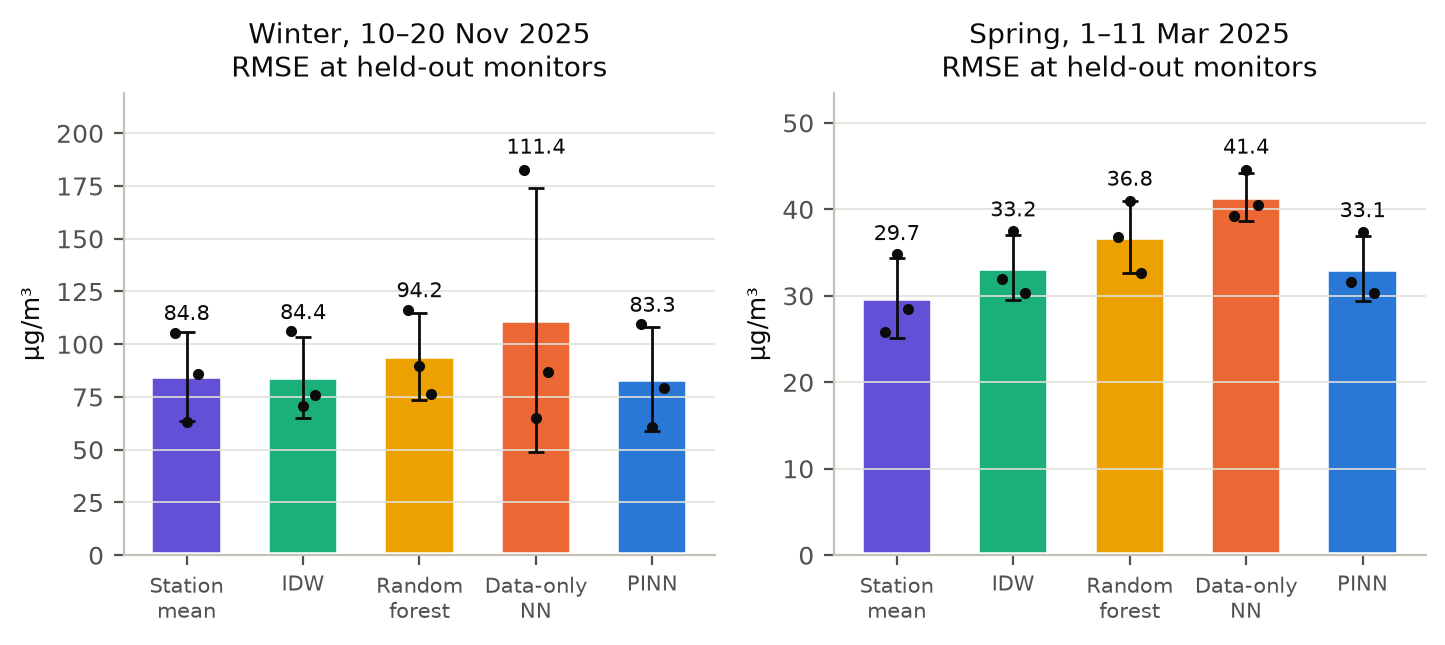

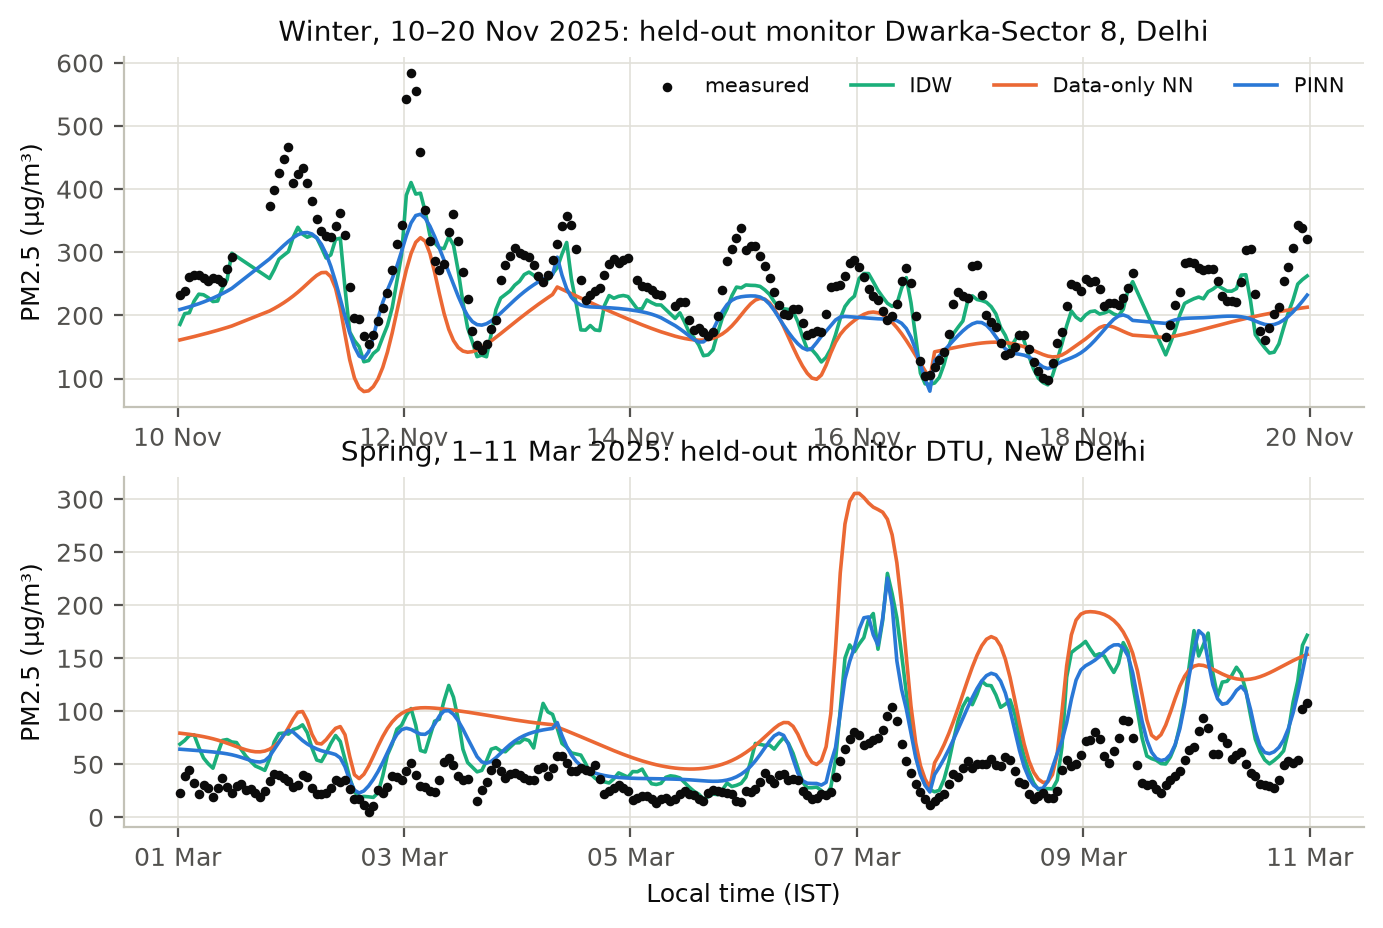

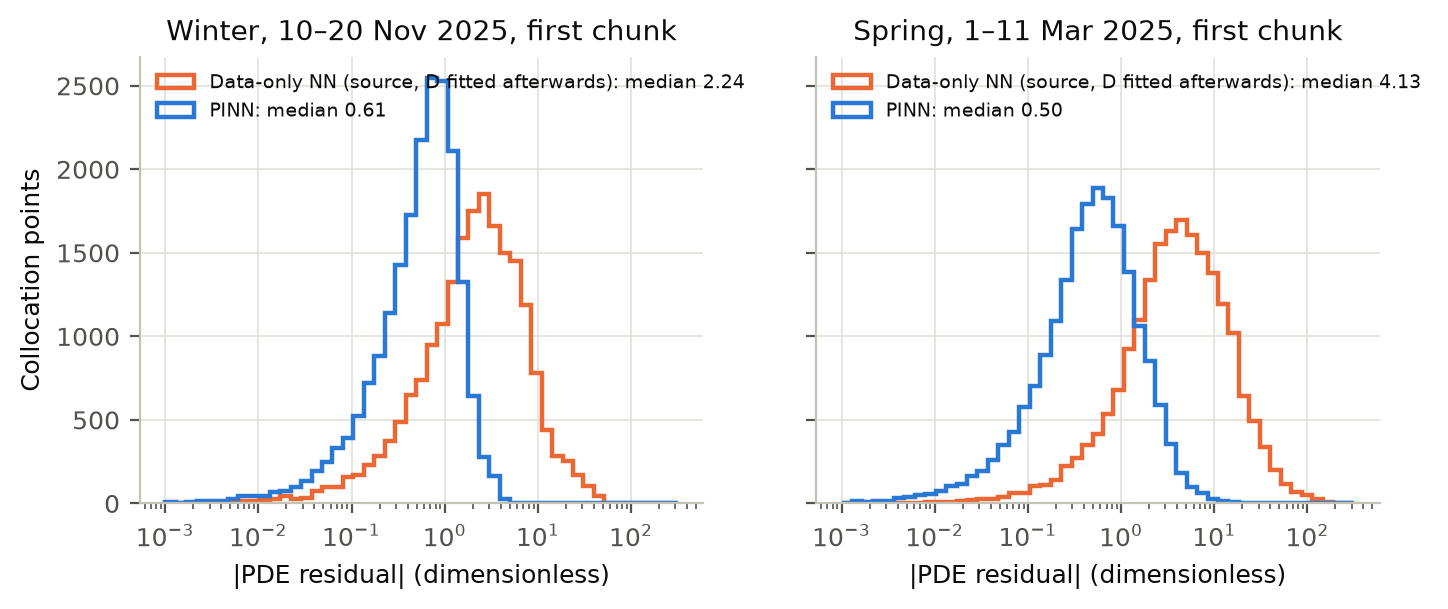

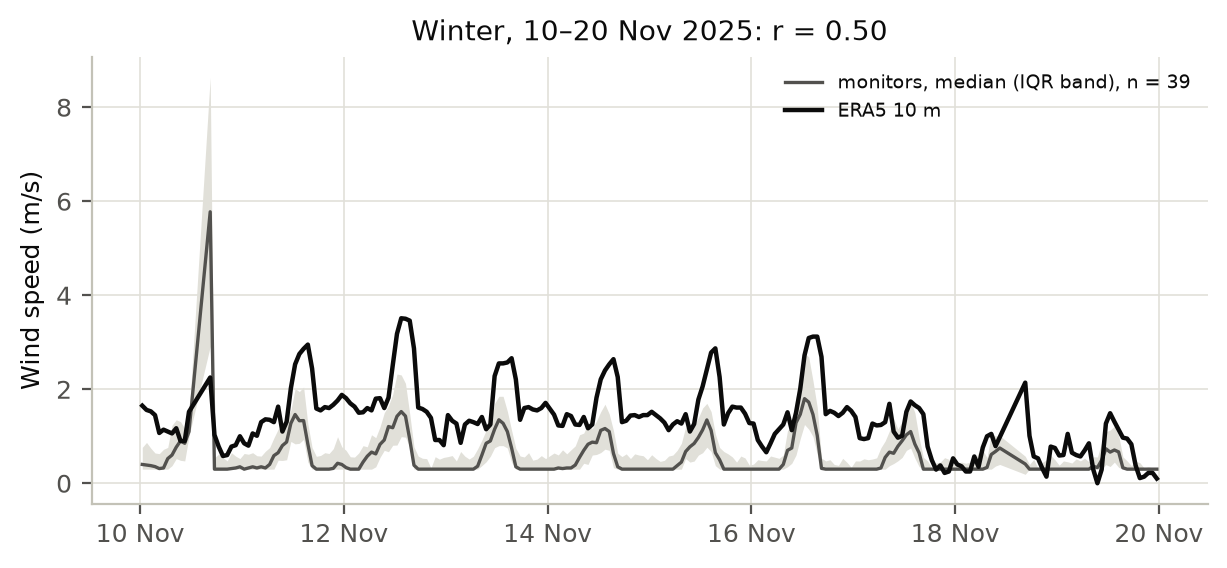

In [15]:
wins = real.pivot_table(index=["window", "seed"], columns="model", values="rmse")
print("PINN better than data-only NN in", int((wins.PINN < wins.DataOnlyNN).sum()), "of", len(wins), "runs")
print("PINN best of all five models in", int((wins[order].idxmin(axis=1) == "PINN").sum()), "of", len(wins), "runs")
for f in ("real_comparison", "real_station_series", "real_residual", "real_wind_check"):
    display(Image(filename=str(FIG / f"{f}.png"), width=850))

**Interpretation (OBSERVED).**
* **Physics regularises.** The PINN beats the identical data-only network in every run and is far more stable across
  splits; its fields have a 4–8× smaller PDE residual.
* **It does not beat simple baselines.** In winter the PINN, IDW and the station mean are within a few µg/m³ — much less than
  the split-to-split spread — and in spring the station mean is best. This is an honest negative result.
* **Why.** The twin shows the method works when the model is right, so the gap is model mismatch: a strong city-wide common
  signal (r ≈ 0.7), uncertain transport wind (monitor anemometers correlate with ERA5 at only r ≈ 0.5), no regional inflow,
  no entrainment and no secondary aerosol formation. The learned $D$ again varies widely (37–266 m²/s) between chunks.

## 6. Sensitivity analysis

Two questions: how sensitive is the **physical model** to its parameters (forward sensitivity, reference solver), and how
sensitive is the **PINN** to the physics weight $w_p$?

The elasticity $\varepsilon_p = \partial \ln \bar C / \partial \ln p$ is estimated from the end points of each sweep.

elasticity of station-mean concentration: {'D': np.float64(-0.026), 'H_min': np.float64(-0.347), 'lam': np.float64(-0.148)}


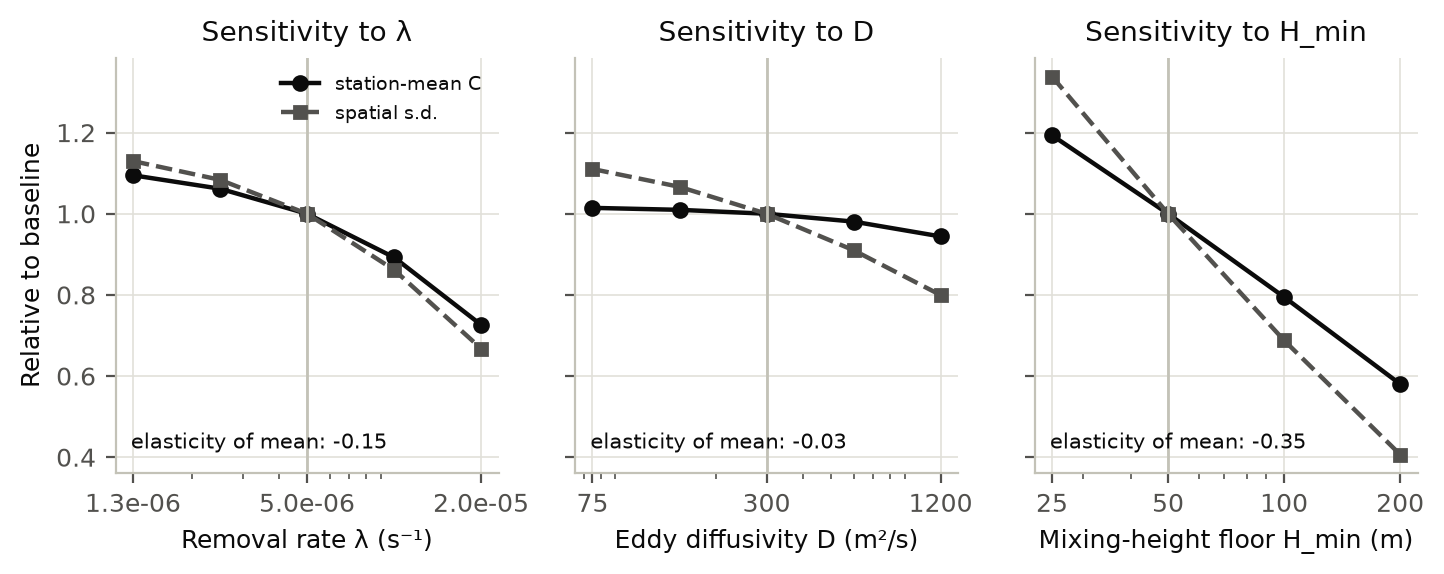

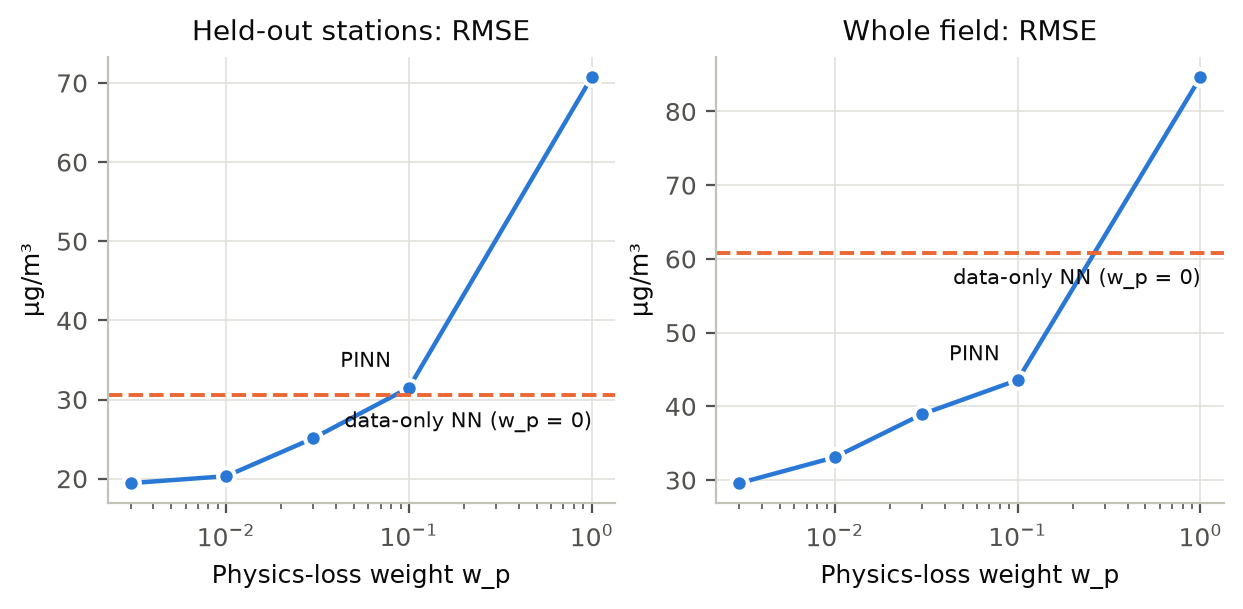

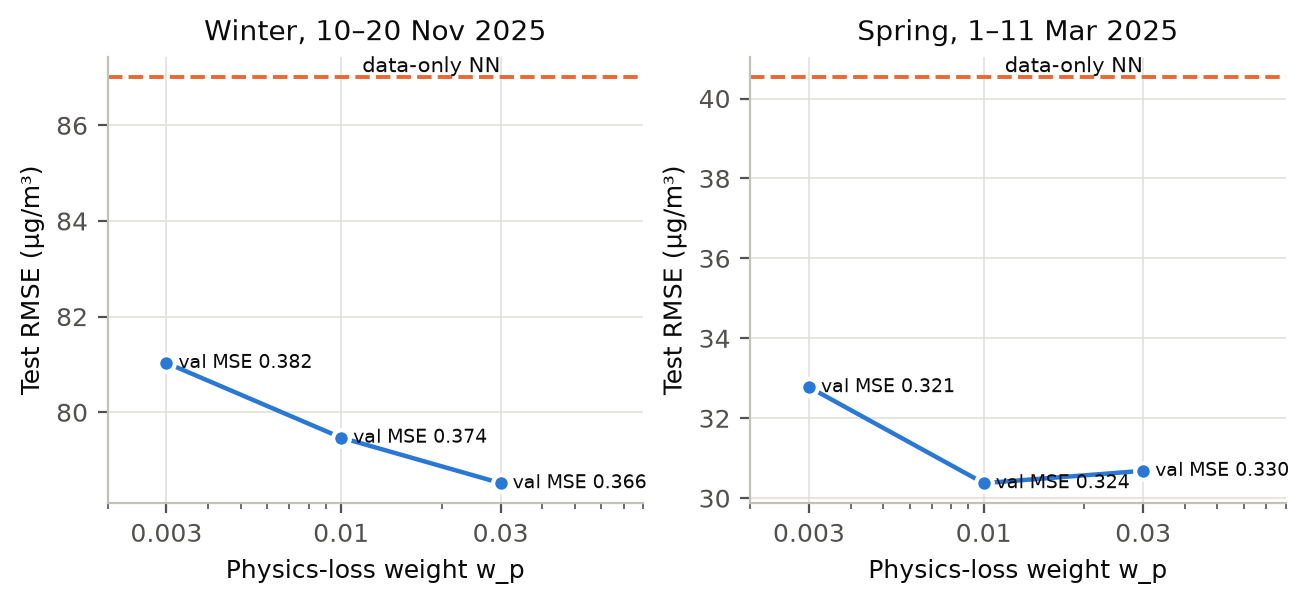

In [16]:
sens = pd.read_csv("results/metrics/twin_forward_sensitivity.csv")
el = {}
for p, d in sens.groupby("param"):
    d = d.sort_values("value")
    el[p] = np.log(d["mean"].iloc[-1] / d["mean"].iloc[0]) / np.log(d.value.iloc[-1] / d.value.iloc[0])
print("elasticity of station-mean concentration:", {k_: round(v, 3) for k_, v in el.items()})
for f in ("twin_forward_sensitivity", "twin_wp_sweep", "real_wp_sweep"):
    display(Image(filename=str(FIG / f"{f}.png"), width=850))

**Interpretation.** Station concentrations are almost insensitive to $D$ (elasticity ≈ −0.03), mildly sensitive to $\lambda$,
and most sensitive to the mixing-height floor $H_{\min}$ — a modelling choice, which we flag as a limitation. For the PINN,
$w_p$ around 0.003–0.01 is best on the twin; at $w_p \ge 0.1$ the PDE term dominates the gradient and the network under-fits
the data, a known PINN pathology (gradient imbalance). On real data the conclusion is unchanged across $w_p\in[0.003,0.03]$.

## 7. Conclusions and limitations

* When its assumptions hold, the physics constraint improves generalisation to unseen locations, especially away from stations,
  and yields physically consistent fields.
* On observed Delhi data the physics still stabilises the network and enforces consistency, but the simplified model does not
  outperform simple interpolation; the main limitations are the uniform wind, unknown inflow boundary, missing entrainment and
  chemistry, and a strong city-wide common signal.
* The eddy diffusivity is not identifiable at Pe ~ 10²–10³; the diurnal emission profile is.

**Reproduce everything** (from the project root):
```bash
.venv/bin/python -m pytest                                   # 50 tests
.venv/bin/python -m src.data.download                        # needs OPENAQ_API_KEY in .env
.venv/bin/python -m experiments.prepare_real
.venv/bin/python -m experiments.make_synthetic_twin
.venv/bin/python -m experiments.run_twin --wp 0.01 --seed 42  # repeat for seeds 1, 2, 3 and the w_p sweep
.venv/bin/python -m experiments.run_real --window winter --seed 42   # and spring; seeds 1, 2
.venv/bin/python -m experiments.make_figures_twin
.venv/bin/python -m experiments.make_figures_real
```